# Holoviews

Description
- HoloViews is an open-source Python library designed to make data analysis and visualization seamless and simple.

Resources:
- [GitHub] https://github.com/holoviz/holoviews
- [Demos] https://holoviews.org/gallery/index.html#demos
- [Examples] https://github.com/holoviz/holoviews/tree/main/examples

Source and license:
- Some of these examples are adapted from the HoloViews gallery (the Lorenz attractor demo) (https://holoviews.org/gallery/index.html), Copyright (c) 2005, holoviz, licensed under BSD-3-Clause. That code stays under its own license; see [THIRD_PARTY_NOTICES.md](../../../../THIRD_PARTY_NOTICES.md).

## Example 1

Lorenz Attractor Example

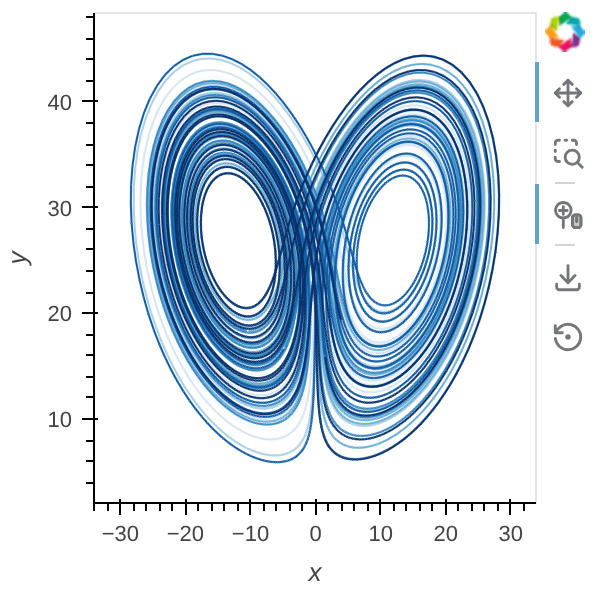

In [1]:
import numpy as np
import holoviews as hv
from scipy.integrate import odeint

hv.extension('bokeh', 'matplotlib')

sigma = 10
rho = 28
beta = 8.0/3
theta = 3 * np.pi / 4

def lorenz(xyz, t):
    x, y, z = xyz
    x_dot = sigma * (y - x)
    y_dot = x * rho - x * z - y
    z_dot = x * y - beta* z
    return [x_dot, y_dot, z_dot]

initial = (-10, -7, 35)
t = np.arange(0, 100, 0.006)

solution = odeint(lorenz, initial, t)

x = solution[:, 0]
y = solution[:, 1]
z = solution[:, 2]
xprime = np.cos(theta) * x - np.sin(theta) * y


paths = zip(np.array_split(xprime, 7), np.array_split(z, 7))
lorenzian = hv.Path([{('x', 'y'): np.array(d).T, 'index': i}
                     for i, d in enumerate(paths)], vdims='index')

lorenzian.opts(color='index', cmap='Blues', line_width=1)

## Example 2

Create an area chart using matplotlib

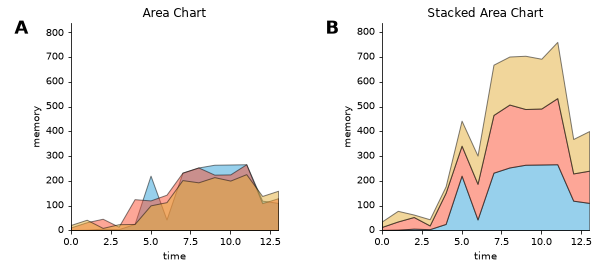

In [2]:
import numpy as np
import holoviews as hv
from holoviews import opts

hv.extension('matplotlib')
hv.output(fig='png')

# create some example data
python=np.array([2, 3, 7, 5, 26, 221, 44, 233, 254, 265, 266, 267, 120, 111])
pypy=np.array([12, 33, 47, 15, 126, 121, 144, 233, 254, 225, 226, 267, 110, 130])
jython=np.array([22, 43, 10, 25, 26, 101, 114, 203, 194, 215, 201, 227, 139, 160])

dims = dict(kdims='time', vdims='memory')
python = hv.Area(python, label='python', **dims)
pypy   = hv.Area(pypy,   label='pypy',   **dims)
jython = hv.Area(jython, label='jython', **dims)

overlay = (python * pypy * jython).opts(opts.Area(alpha=0.5))
overlay.relabel("Area Chart") + hv.Area.stack(overlay).relabel("Stacked Area Chart")